In [4]:
import sys
sys.path.insert(0, "/home/aryan/hiv-latency-sc/plotting")
import config
print("config loaded, checkpoints at:", config.CHECKPOINTS)

config loaded, checkpoints at: /scratch/maid/DP2_PBMC/checkpoints


In [5]:
import scanpy as sc
import config

In [6]:
adata = sc.read_h5ad(config.CHECKPOINTS / "02_filtered.h5ad")
print(adata)
print("adata loaded, shape:", adata.shape)

AnnData object with n_obs × n_vars = 163951 × 24051
    obs: 'sample', 'animal', 'week', 'group', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'TSS.enrichment', 'nucleosome_signal', 'keep_reason', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet', 'stage_01', 'stage_02'
    layers: None (.X)
adata loaded, shape: (163951, 24051)


In [7]:
print("X max = ", adata.X.max())
print("X min = ", adata.X.min())
print(adata.obs['keep_reason'].value_counts())

X max =  11053.0
X min =  0.0
keep_reason
rna_pass       158633
atac_rescue      5318
Name: count, dtype: int64


In [8]:
adata.layers["counts"] = adata.X.copy()
print("saved raw counts to layers['counts']")
print("layers now:", list(adata.layers.keys()))

saved raw counts to layers['counts']
layers now: [None, 'counts']


In [9]:
print(type(adata.layers))
for k in adata.layers.keys():
    v = adata.layers[k]
    print(repr(k), "->", type(v), getattr(v, "shape", "no shape"))

<class 'anndata._core.aligned_mapping.Layers'>
None -> <class 'scipy.sparse._csr.csr_matrix'> (163951, 24051)
'counts' -> <class 'scipy.sparse._csr.csr_matrix'> (163951, 24051)


In [10]:
import numpy as np
same_as_X = adata.layers[None] is adata.X
print("layers[None] IS adata.X:", same_as_X)
print("counts IS adata.X:", adata.layers["counts"] is adata.X)

layers[None] IS adata.X: True
counts IS adata.X: False


In [11]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
print("After normalization and log 1p:")
print(".  X max = ", round(float(adata.X.max()), 3), "was 11053")
print(".  Count layer max = ", float(adata.layers['counts'].max()))

After normalization and log 1p:
.  X max =  9.156 was 11053
.  Count layer max =  11053.0


HVGs selected: 2000
HVGs selected: highly_variable
False    22051
True      2000
Name: count, dtype: int64
highly_variable_nbatches
1     793
2    1207
Name: count, dtype: int64


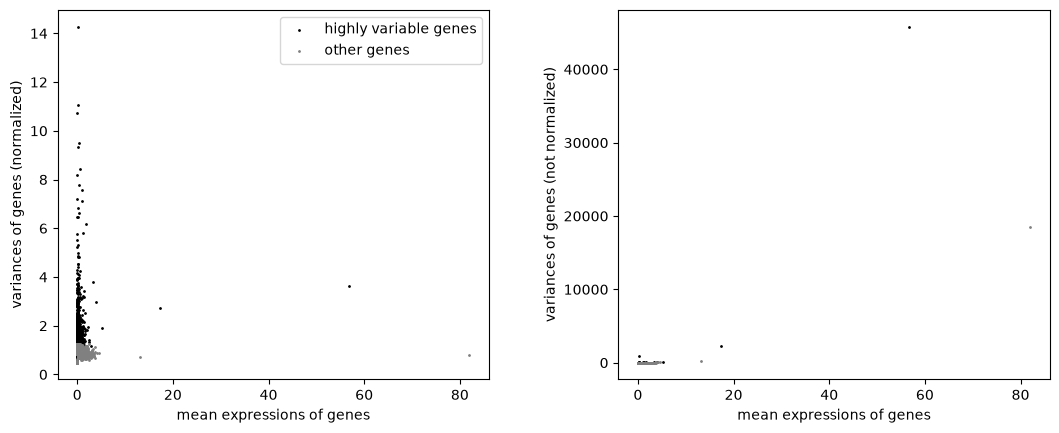

In [12]:
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=2000, batch_key="batch", layer="counts")

print("HVGs selected:", adata.var["highly_variable"].sum())
print("HVGs selected:", adata.var["highly_variable"].value_counts())
print(adata.var.loc[adata.var["highly_variable"], "highly_variable_nbatches"].value_counts().sort_index())

sc.pl.highly_variable_genes(adata)

In [13]:
adata.raw = adata
print("adata.raw set to adata, shape:", adata.raw.shape)

adata.raw set to adata, shape: (163951, 24051)


In [14]:
adata.raw.shape

(163951, 24051)

In [15]:
adata = adata[:, adata.var["highly_variable"]].copy()
print("adata filtered to HVGs, shape:", adata.shape)
print("adata.raw shape:", adata.raw.shape)

adata filtered to HVGs, shape: (163951, 2000)
adata.raw shape: (163951, 24051)


In [16]:
#scaling the HVGs
sc.pp.scale(adata, max_value = 10)
print("After scaling:")
print(".  X max = ", round(float(adata.X.max()), 3))
print(".  X min = ", round(float(adata.X.min()), 3))
print(".  Mean of a few genes:", np.mean(adata.X[:, :5], axis=0))

/usr/lib/python3.12/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


After scaling:
.  X max =  10.0
.  X min =  -3.747
.  Mean of a few genes: [-9.73273367e-04 -5.56491971e-03 -1.01352255e-02 -1.00069823e-02
 -2.11100940e-14]


In [17]:
sc.tl.pca(adata, n_comps=50, svd_solver="arpack", random_state=config.SEED)
print("PCA done, shape:", adata.obsm["X_pca"].shape)
print("Variance explained by the first 10 PCs:", adata.uns["pca"]["variance_ratio"][:10])

PCA done, shape: (163951, 50)
Variance explained by the first 10 PCs: [0.05225115 0.02860785 0.01496942 0.00905593 0.006257   0.00509215
 0.00467154 0.00407739 0.00339637 0.00333762]


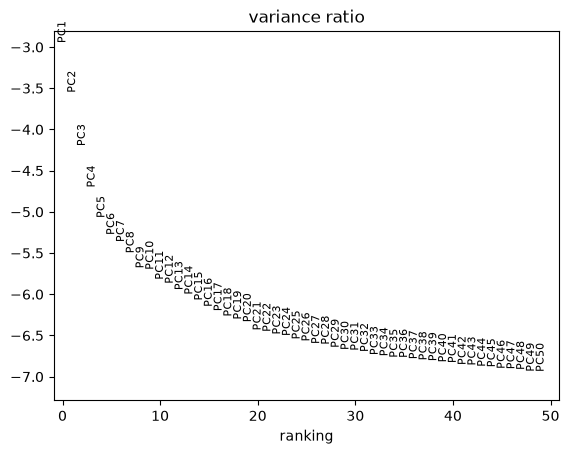

In [18]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

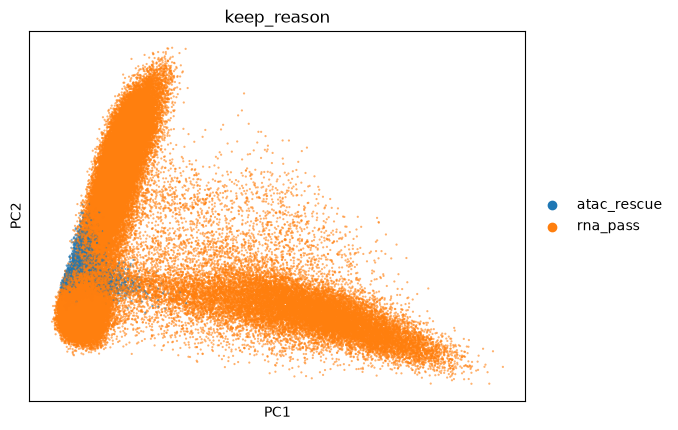

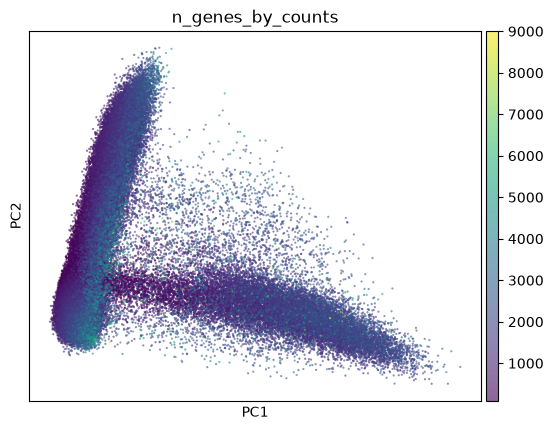

In [19]:
sc.pl.pca(adata, color="keep_reason", components="1, 2", size=10, alpha=0.6)
sc.pl.pca(adata, color="n_genes_by_counts", components="1, 2", size=10, alpha=0.6)

In [20]:
adata.uns["stage_03"] = {
    "scanpy": sc.__version__,
    "n_hvg": int(adata.n_vars),
    "n_pcs_computed": 50,
    "n_pcs_chosen": 30,              
    "hvg_flavor": "seurat_v3",
    "hvg_batch_aware": True,
    "normalization": "normalize_total(1e4) + log1p",
    "seed": config.SEED,
}
out = config.CHECKPOINTS / "03_pca.h5ad"
adata.write_h5ad(out, compression="gzip")
print(f"saved {out.name}: {adata.shape[0]:,} cells x {adata.shape[1]:,} HVGs, "
      f"PCA {adata.obsm['X_pca'].shape[1]} comps, full genes in .raw ({adata.raw.shape[1]:,})")

/tmp/ipykernel_142481/3958088216.py:2: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  "scanpy": sc.__version__,


saved 03_pca.h5ad: 163,951 cells x 2,000 HVGs, PCA 50 comps, full genes in .raw (24,051)


In [21]:
!pip install harmonypy

In [22]:
print("dtype:", adata.obs["batch"].dtype)
print(adata.obs["batch"].value_counts(dropna=False))
print("n unique:", adata.obs["batch"].nunique())
print("categories (if categorical):",
      adata.obs["batch"].cat.categories.tolist() if hasattr(adata.obs["batch"], "cat") else "not categorical")

dtype: category
batch
1    98251
2    65700
Name: count, dtype: int64
n unique: 2
categories (if categorical): ['1', '2']


In [23]:
import harmonypy
import numpy as np

ho = harmonypy.run_harmony(
    adata.obsm["X_pca"].astype(np.float64),
    adata.obs,
    vars_use=["batch"],
)

Z = ho.Z_corr                                
print("Z_corr shape:", Z.shape)                
assert Z.shape == adata.obsm["X_pca"].shape, \
    f"shape mismatch: {Z.shape} vs {adata.obsm['X_pca'].shape}"

adata.obsm["X_pca_harmony"] = np.asarray(Z)
print("harmonized embedding stored:", adata.obsm["X_pca_harmony"].shape)

2026-10-22 21:27:57,705 - harmonypy - INFO - Running Harmony
2026-10-22 21:27:57,705 - harmonypy - INFO -   Parameters:
2026-10-22 21:27:57,705 - harmonypy - INFO -     max_iter_harmony: 10
2026-10-22 21:27:57,705 - harmonypy - INFO -     max_iter_kmeans: 4
2026-10-22 21:27:57,706 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-10-22 21:27:57,706 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-10-22 21:27:57,706 - harmonypy - INFO -     nclust: 100
2026-10-22 21:27:57,706 - harmonypy - INFO -     block_size: 0.05
2026-10-22 21:27:57,706 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-10-22 21:27:57,707 - harmonypy - INFO -     theta: [2. 2.]
2026-10-22 21:27:57,707 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-10-22 21:27:57,707 - harmonypy - INFO -     verbose: True
2026-10-22 21:27:57,707 - harmonypy - INFO -     random_state: 0
2026-10-22 21:27:57,707 - harmonypy - INFO -   Data: 50 PCs × 163951 cells
2026-10-22 21:27:57,708 - harmonypy - INFO -   Ba

2026-10-22 21:27:57,752 - harmonypy - INFO - Computing initial centroids...
2026-10-22 21:27:57,871 - harmonypy - INFO - Initialization complete.
2026-10-22 21:27:57,871 - harmonypy - INFO - Iteration 1 of 10
2026-10-22 21:27:58,000 - harmonypy - INFO - Iteration 2 of 10
2026-10-22 21:27:58,131 - harmonypy - INFO - Iteration 3 of 10
2026-10-22 21:27:58,232 - harmonypy - INFO - Iteration 4 of 10
2026-10-22 21:27:58,336 - harmonypy - INFO - Converged after 4 iterations


Z_corr shape: (163951, 50)
harmonized embedding stored: (163951, 50)


In [24]:
# nwighbors + UMAP on raw PCA
sc.pp.neighbors(adata, n_pcs=config.N_PCS, use_rep="X_pca", key_added="neighbors_raw")
sc.tl.umap(adata, neighbors_key="neighbors_raw")
adata.obsm["X_umap_raw"] = adata.obsm["X_umap"].copy()

#neighbors + UMAP on harmonized PCA
sc.pp.neighbors(adata, n_pcs=config.N_PCS, use_rep="X_pca_harmony", key_added="neighbors_harmony")
sc.tl.umap(adata, neighbors_key="neighbors_harmony")
adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()

print("UMAPs computed, stored in .obsm['X_umap_raw'] and .obsm['X_umap_harmony']")

/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


UMAPs computed, stored in .obsm['X_umap_raw'] and .obsm['X_umap_harmony']


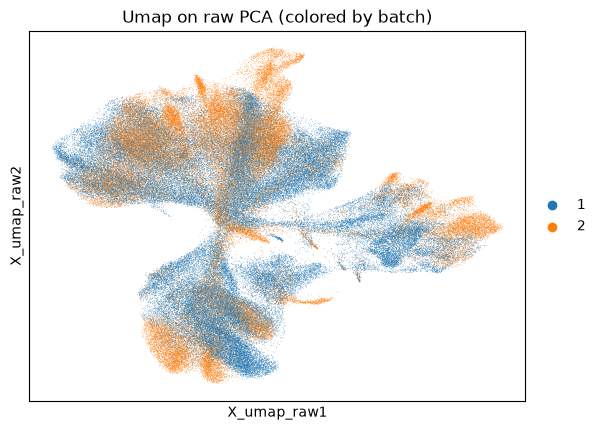

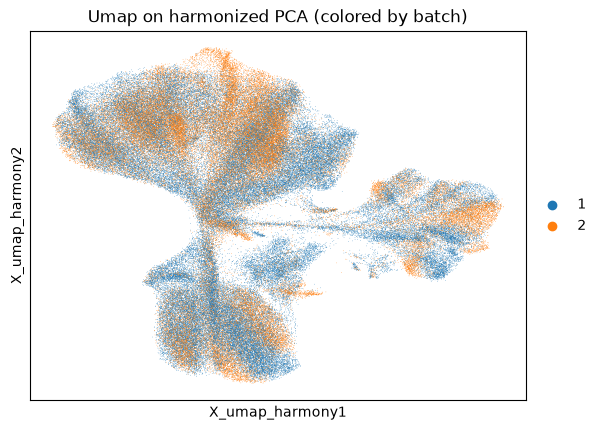

In [25]:
sc.pl.embedding(adata, "X_umap_raw", color="batch", title="Umap on raw PCA (colored by batch)")
sc.pl.embedding(adata, "X_umap_harmony", color="batch", title="Umap on harmonized PCA (colored by batch)")

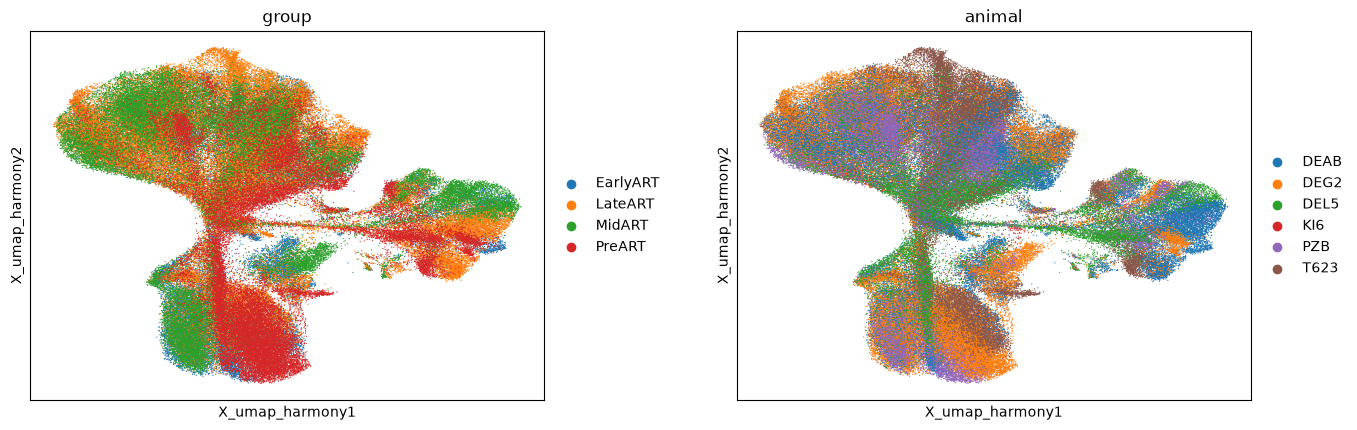

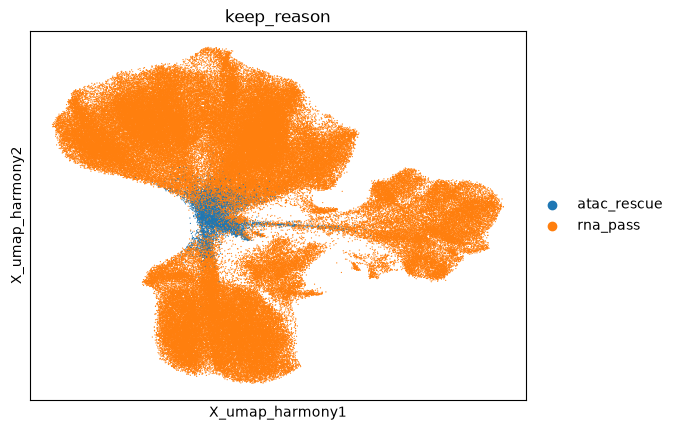

In [32]:
sc.pl.embedding(adata, "X_umap_harmony", color=["group", "animal"], size=3, ncols=2, wspace=0.25, frameon=True)
sc.pl.embedding(adata, "X_umap_harmony", color="keep_reason", size=3)   

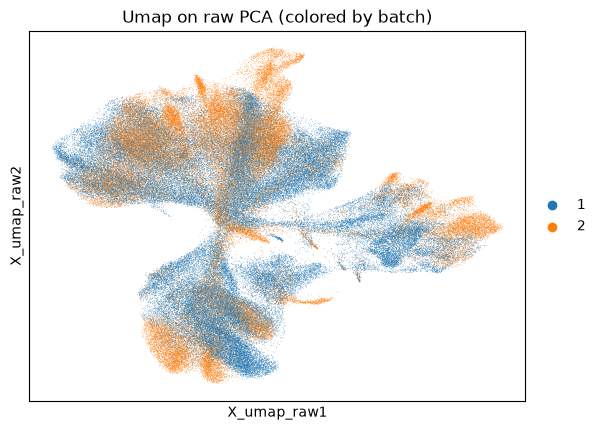

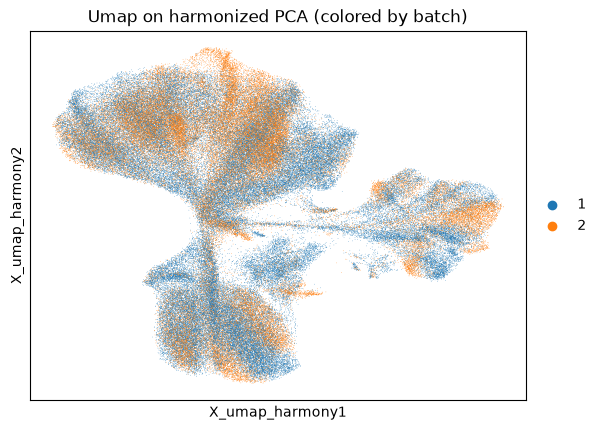

In [27]:
sc.pl.embedding(adata, "X_umap_raw", color="batch", title="Umap on raw PCA (colored by batch)")
sc.pl.embedding(adata, "X_umap_harmony", color="batch", title="Umap on harmonized PCA (colored by batch)")

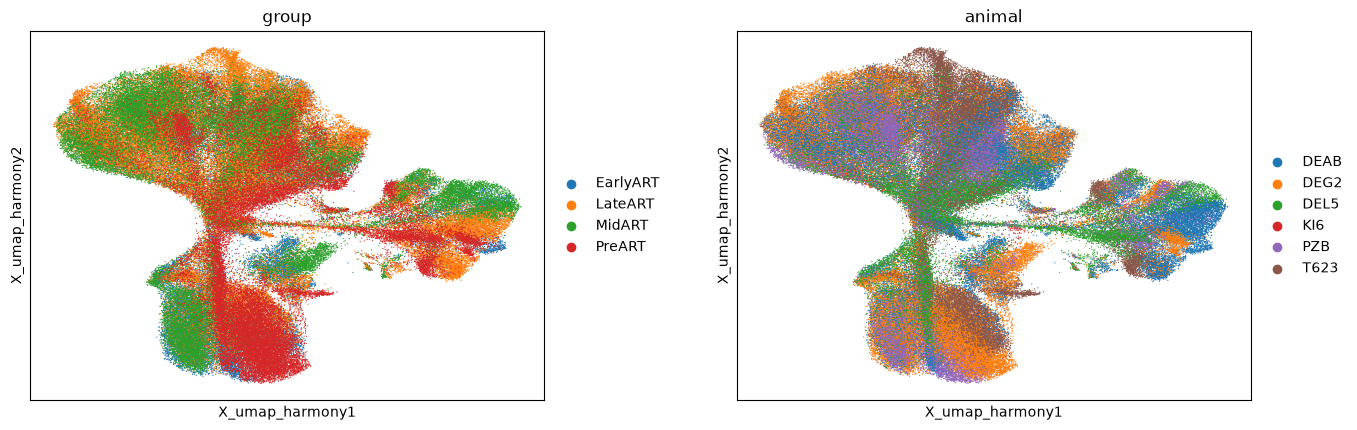

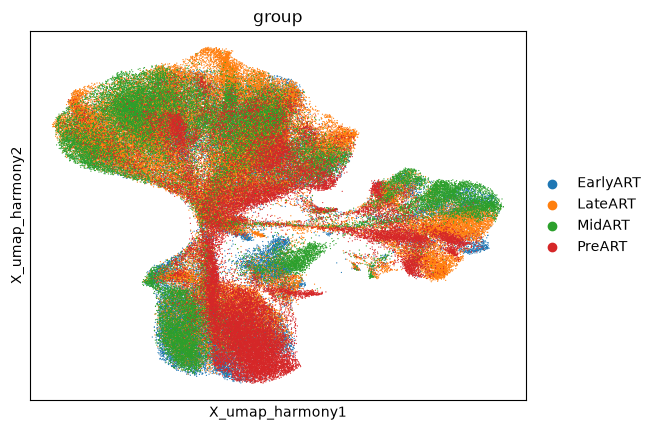

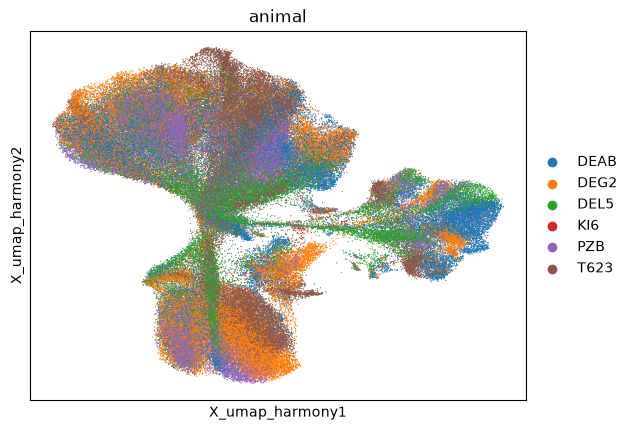

In [33]:
sc.pl.embedding(adata, "X_umap_harmony", color=["group", "animal"], size=3, ncols=2, wspace=0.25, frameon=True)
sc.pl.embedding(adata, "X_umap_harmony", color="group",  size=3)
sc.pl.embedding(adata, "X_umap_harmony", color="animal", size=3)